# Detecting leaf disease from hyperspectral spectra, and validating it honestly

Hyperspectral cameras such as the Specim IQ record about 200 narrow bands per pixel, from 400 to 1000 nm.
Diseased leaves change these spectra: chlorophyll loss, necrosis or a fungal layer on the surface.
This tutorial runs offline on **synthetic** grapevine-like leaves with three classes (healthy, esca-like, powdery-mildew-like).

You will:

1. inspect spectra and choose quality rules that do not remove the symptoms themselves;
2. compute narrow-band indices and summarise pixels to one spectrum per leaf;
3. see how a **random pixel split overstates accuracy**, and validate by leaf instead;
4. see how **date and disease can be confounded**, and what that does to a model;
5. screen for unusual leaves with a one-class model trained on healthy leaves only;
6. find which wavelength regions the model relies on.

**About the synthetic data.** The size and shape of the disease effects are illustrative choices. They follow the general
direction of changes described in the literature, but they are not fitted to measured leaves.
The lessons here are about **method**, not about real disease spectra.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from leafspec import aggregate, bands, indices, models, preprocess, synthetic, validate

plt.rcParams.update({"figure.dpi": 90})
COLOURS = {"healthy": "#2e7d32", "esca": "#8d6e63", "powdery_mildew": "#7e57c2"}

## 1. Spectra

90 leaves (30 per class), 3 dates, 120 pixels per leaf, one leaf per image. Diseased leaves have a severity between mild
and severe, and only part of their pixels are lesions, as on real leaves.

(10800, 204) pixels x bands | {'esca': 30, 'healthy': 30, 'powdery_mildew': 30}


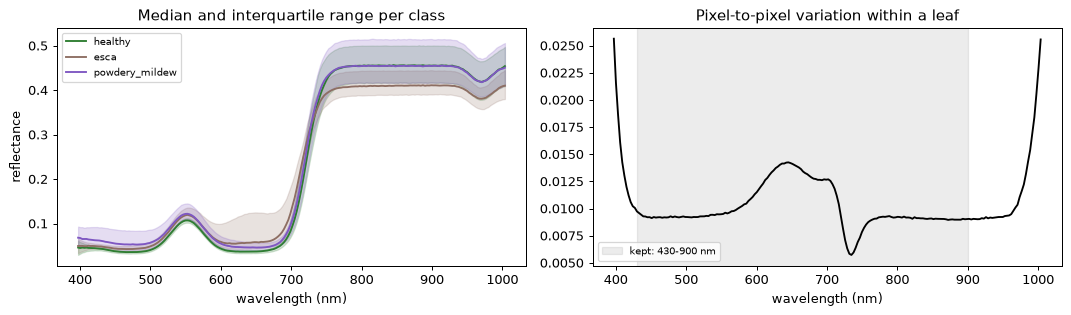

In [2]:
px = synthetic.make_leaves(synthetic.BALANCED, pixels_per_leaf=120, seed=4, date_effect=2.5)
print(px.values.shape, "pixels x bands |", px.meta.groupby("label")["leaf"].nunique().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for label, c in COLOURS.items():
    v = px.values[px.meta["label"].to_numpy() == label]
    q25, q50, q75 = np.percentile(v, [25, 50, 75], axis=0)
    ax[0].plot(px.wavelengths, q50, color=c, label=label)
    ax[0].fill_between(px.wavelengths, q25, q75, color=c, alpha=0.2)
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("reflectance")
ax[0].legend(fontsize=8)
ax[0].set_title("Median and interquartile range per class")
within_leaf_sd = px.meta.assign(i=range(len(px))).groupby("leaf")["i"].apply(lambda i: px.values[i].std(axis=0))
ax[1].plot(px.wavelengths, np.mean(np.vstack(within_leaf_sd), axis=0), color="k")
ax[1].axvspan(430, 900, color="grey", alpha=0.15, label="kept: 430-900 nm")
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_title("Pixel-to-pixel variation within a leaf")
ax[1].legend(fontsize=8)
plt.tight_layout()

The right panel shows why the ends of the range are trimmed: noise is much larger there. Choose the range from a plot like this
for your own sensor, not from a fixed rule.

## 2. Quality rules that keep the symptoms

A leaf mask by NDVI removes background, but a strict threshold also removes **brown, necrotic lesion pixels**, the very
symptoms being studied. Compare two thresholds:

In [3]:
rows = {}
for min_ndvi in (0.2, 0.5):
    q = preprocess.quality_mask(px, max_reflectance=1.0, min_nir=0.1, min_ndvi=min_ndvi)
    removed = px.meta.loc[~q["ok"]]
    rows[f"NDVI >= {min_ndvi}"] = {
        "pixels removed": len(removed),
        "of which esca lesions": int(((removed["label"] == "esca") & removed["lesion"]).sum()),
        "of which healthy": int((removed["label"] == "healthy").sum()),
    }
pd.DataFrame(rows).T

,pixels removed,of which esca lesions,of which healthy
NDVI >= 0.2,0,0,0
NDVI >= 0.5,727,727,0


In [4]:
q = preprocess.quality_mask(px, max_reflectance=1.0, min_nir=0.1, min_ndvi=0.2)
px_ok = preprocess.trim(px.subset(q["ok"].to_numpy()), 430, 900)
print(f"kept {len(px_ok)} of {len(px)} pixels, {px_ok.wavelengths.size} bands")

kept 10800 of 10800 pixels, 158 bands


## 3. Indices and leaf spectra

Labels are given per leaf, so pixels are summarised to one median spectrum per leaf.
Three narrow-band indices:
- NDVI (800/670 nm): greenness;
- PRI (531/570 nm): sensitive to photosynthetic efficiency and pigments;
- red-edge position: the steepest point between 680 and 750 nm, which moves to shorter wavelengths when chlorophyll falls.

,ndvi,pri,red_edge_nm
label,,,
esca,0.764,-0.033,716.303
healthy,0.839,-0.021,721.533
powdery_mildew,0.811,-0.004,721.367


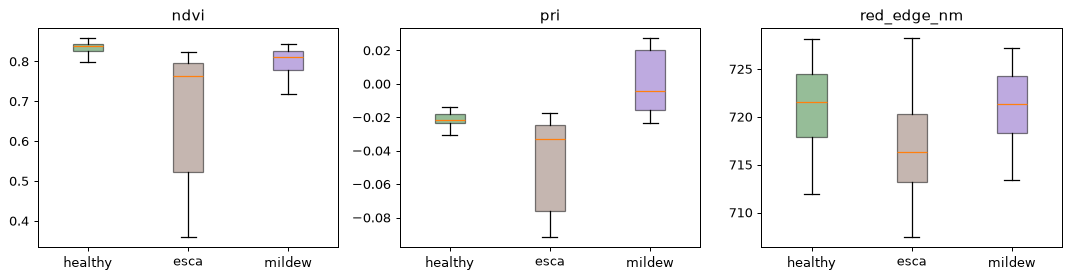

In [5]:
leaves = aggregate.leaf_spectra(px_ok, by="leaf", carry=("label", "date"))
tab = indices.index_table(leaves)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, col in zip(ax, ["ndvi", "pri", "red_edge_nm"], strict=True):
    data = [tab.loc[tab["label"] == k, col] for k in COLOURS]
    bp = a.boxplot(data, patch_artist=True)
    for patch, c in zip(bp["boxes"], COLOURS.values(), strict=True):
        patch.set_facecolor(c)
        patch.set_alpha(0.5)
    a.set_xticks([1, 2, 3], ["healthy", "esca", "mildew"])
    a.set_title(col)
plt.tight_layout()
tab.groupby("label")[["ndvi", "pri", "red_edge_nm"]].median().round(3)

## 4. The most common mistake: splitting pixels at random

Pixels of one leaf are near-copies. With a random split, pixels of every test leaf are also in the training set,
so a flexible model can recognise **the leaf** rather than the disease. Holding out whole leaves gives the honest estimate.

In [6]:
y_px, g_px = px_ok.meta["label"].to_numpy(), px_ok.meta["leaf"].to_numpy()
sub = np.random.default_rng(0).choice(len(y_px), 5000, replace=False)
rf = models.make_classifier("rf", n_estimators=200)
comparison = validate.compare_splits(rf, px_ok.values[sub], y_px[sub], g_px[sub], n_splits=5)

y_leaf, g_leaf = leaves.meta["label"].to_numpy(), leaves.meta["leaf"].to_numpy()
leaf_folds = validate.grouped_folds(y_leaf, g_leaf, 5, seed=0)
leaf_level = validate.scores(y_leaf, validate.out_of_fold(rf, leaves.values, y_leaf, leaf_folds))
comparison.loc["leaf spectra, grouped split"] = [leaf_level["balanced_accuracy"], leaf_level["macro_f1"]]
comparison.round(3)

,balanced_accuracy,macro_f1
random split (ignores leaves),0.978,0.978
grouped split (whole leaves held out),0.752,0.751
"leaf spectra, grouped split",0.900,0.900


In [7]:
leaf_level["confusion"]

,esca,healthy,powdery_mildew
esca,26,4,0
healthy,0,27,3
powdery_mildew,2,0,28


The pixel-level random split looks clearly better than either honest estimate. That difference is leakage, not skill.
The remaining errors are mostly between healthy and diseased leaves, not between the two diseases.

## 5. When date and disease are confounded

In field campaigns, healthy leaves are often measured early in the season and symptomatic leaves late, because symptoms
develop over summer. Leaves also change with the season. A model can then learn **"late season" instead of "diseased"**,
and cross-validation within the same campaign will not reveal it.

Train on a confounded campaign (mostly healthy in May, mostly diseased in August), then test on an independent campaign
where every date has every class:

In [8]:
def leaf_table(design, seed):
    p = preprocess.trim(synthetic.make_leaves(design, pixels_per_leaf=60, seed=seed, date_effect=2.5), 430, 900)
    return aggregate.leaf_spectra(p, by="leaf")

conf, indep = leaf_table(synthetic.CONFOUNDED, 11), leaf_table(synthetic.BALANCED, 12)
def binary(s):
    return np.where(s.meta["label"] == "healthy", "healthy", "diseased")

yc, yi = binary(conf), binary(indep)
print("training campaign, healthy share by date:",
      conf.meta.assign(h=yc == "healthy").groupby("date")["h"].mean().round(2).to_dict())

model = models.make_classifier("logistic")
cv = validate.scores(yc, validate.out_of_fold(model, conf.values, yc, validate.grouped_folds(yc, conf.meta["leaf"], 5)))
pred = model.fit(conf.values, yc).predict(indep.values)
print(f"cross-validation within the confounded campaign: {cv['balanced_accuracy']:.3f}")
print(f"independent campaign (all classes on all dates):  {validate.scores(yi, pred)['balanced_accuracy']:.3f}")
pd.DataFrame({"date": indep.meta["date"], "truth": yi, "flagged": pred == "diseased"}) \
  .groupby(["date", "truth"])["flagged"].mean().unstack().rename(columns=lambda c: f"share flagged, {c}").round(2)

training campaign, healthy share by date: {'2021-05-28': 1.0, '2021-07-23': 0.67, '2021-08-13': 0.05}
cross-validation within the confounded campaign: 0.971
independent campaign (all classes on all dates):  0.692


truth,"share flagged, diseased","share flagged, healthy"
date,,
2021-05-28,0.60,0.1
2021-07-23,0.80,0.3
2021-08-13,0.95,0.8


Cross-validation looked excellent, but on independent data **healthy August leaves are mostly flagged as diseased**.
The model learned the season.

**What to do with real data:**
- compare classes **within the same date**;
- or include healthy controls on every date and hold out whole dates;
- and report the design along with the accuracy.

## 6. Screening with a model of healthy leaves only

Labelled diseased leaves are scarce, and early symptoms vary. A one-class SVM learns what healthy leaves look like and scores
how far each new leaf is from that. It is trained on healthy leaves only, and every score comes from a model that did not
see that leaf.

correlation of anomaly score with (hidden) severity, diseased leaves: 0.73


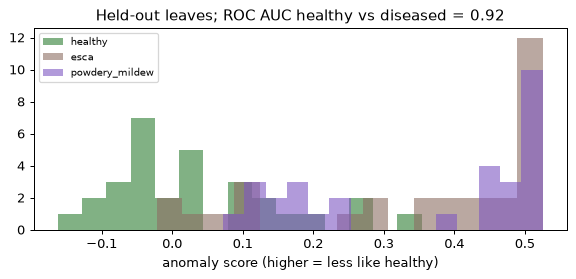

In [9]:
score, auc = validate.one_class_out_of_fold(models.make_one_class(nu=0.1), leaves.values, y_leaf == "healthy",
                                            g_leaf, n_splits=5)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for label, c in COLOURS.items():
    ax.hist(score[y_leaf == label], bins=15, alpha=0.6, color=c, label=label)
ax.set_xlabel("anomaly score (higher = less like healthy)")
ax.legend(fontsize=8)
ax.set_title(f"Held-out leaves; ROC AUC healthy vs diseased = {auc:.2f}")
plt.tight_layout()
sev = leaves.meta.merge(px.meta.groupby("leaf")["severity"].first(), left_on="leaf", right_index=True)["severity"]
print("correlation of anomaly score with (hidden) severity, diseased leaves:",
      round(float(np.corrcoef(score[y_leaf != "healthy"], sev[y_leaf != "healthy"])[0, 1]), 2))

## 7. Which wavelengths matter

Neighbouring bands carry almost the same information, so bands are permuted together in 40 nm windows, on held-out
leaves only. A large drop in accuracy means the model relies on that region. A linear model is used here: flexible models
such as random forests can switch to a neighbouring window when one is shuffled, which hides the importance of a region.

,start_nm,end_nm,mean_drop
0,430.15,470.15,0.216
1,470.15,510.15,0.199
4,590.15,630.15,0.126
6,670.15,710.15,0.105


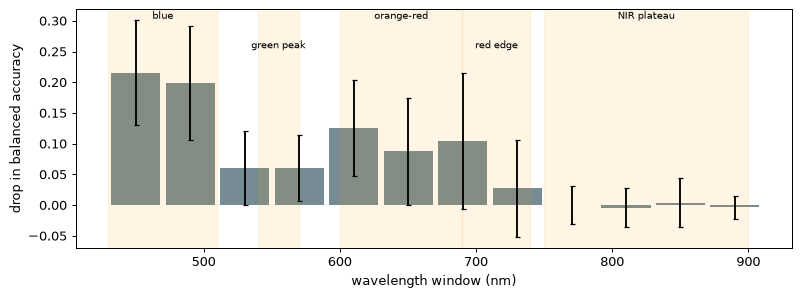

In [10]:
y_bin = np.where(y_leaf == "healthy", "healthy", "diseased")
imp = bands.window_importance(models.make_classifier("logistic"), leaves.values, y_bin, g_leaf,
                              leaves.wavelengths, width_nm=40, n_splits=5, n_repeats=10, seed=0)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(imp["centre_nm"], imp["mean_drop"], width=36, yerr=imp["sd_drop"], color="#546e7a", alpha=0.8, capsize=2)
top = ax.get_ylim()[1]
for lo, hi, name, h in [(430, 510, "blue", 0.95), (540, 570, "green peak", 0.80), (600, 690, "orange-red", 0.95),
                        (690, 740, "red edge", 0.80), (750, 900, "NIR plateau", 0.95)]:
    ax.axvspan(lo, hi, color="orange", alpha=0.10)
    ax.text((lo + hi) / 2, top * h, name, ha="center", fontsize=8)
ax.set_xlabel("wavelength window (nm)")
ax.set_ylabel("drop in balanced accuracy")
plt.tight_layout()
imp.nlargest(4, "mean_drop")[["start_nm", "end_nm", "mean_drop"]].round(3)

In this synthetic data the model relies most on the **blue** windows (where the simulated whitish mildew layer acts),
then on **orange–red** (pigment loss and browning) and the **red edge** (its shift to shorter wavelengths). That is
consistent with how the data were generated, which is a useful check that the method works. With real leaves, compare the result with the spectral regions reported in the literature rather than expecting
a fixed answer, and treat it as a description of the model, not a proof of a mechanism.

## Using real Specim IQ data

`leafspec.io.read_envi` reads a Specim IQ `REFLECTANCE_*.hdr` cube directly. `leafspec.io.read_pixel_table` reads ROI exports
(`image, x, y, label` plus one column per wavelength), including exports with a file-path line and repeated headers.
After that, the steps are the ones above.

Three checks before trusting any accuracy on real leaves:

1. **The unit of validation is the leaf (or plant), never the pixel.**
2. **Date, cultivar and plot are balanced across classes, or held out.**
3. **The reflectance level is plausible.** A healthy leaf has a near-infrared plateau of roughly 0.4–0.5. Much lower values point
   to calibration (white reference, illumination). Indices such as NDVI and SNV-normalised spectra are less sensitive to this
   than absolute reflectance.

**References:** Behmann et al. (2018); Savitzky & Golay (1964); Barnes et al. (1989); Gamon et al. (1992); Horler et al. (1983);
Barker & Rayens (2003); Schölkopf et al. (2001); Roberts et al. (2017); Mahlein (2016).
The full list with DOIs is in the [README](../README.md#references).